In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import sklearn 
import streamlit 
print("FDS environment is ready to use!")

FDS environment is ready to use!


In [2]:
import os 
print("Files inside data/raw:")
for file in os.listdir("../data/raw"):
    print(file)

Files inside data/raw:
Mental_Health_and_Social_Media_Balance_Dataset.csv


In [3]:
import pandas as pd 
df = pd.read_csv("../data/raw/Mental_Health_and_Social_Media_Balance_Dataset.csv")
df.head()

,User_ID,Age,Gender,Daily_Screen_Time(hrs),Sleep_Quality(1-10),Stress_Level(1-10),Days_Without_Social_Media,Exercise_Frequency(week),Social_Media_Platform,Happiness_Index(1-10)
0,U001,44,Male,3.1,7.0,6.0,2.0,5.0,Facebook,10.0
1,U002,30,Other,5.1,7.0,8.0,5.0,3.0,LinkedIn,10.0
2,U003,23,Other,7.4,6.0,7.0,1.0,3.0,YouTube,6.0
3,U004,36,Female,5.7,7.0,8.0,1.0,1.0,TikTok,8.0
4,U005,34,Female,7.0,4.0,7.0,5.0,1.0,X (Twitter),8.0


In [4]:
df.shape
df.columns.tolist()

['User_ID',
 'Age',
 'Gender',
 'Daily_Screen_Time(hrs)',
 'Sleep_Quality(1-10)',
 'Stress_Level(1-10)',
 'Days_Without_Social_Media',
 'Exercise_Frequency(week)',
 'Social_Media_Platform',
 'Happiness_Index(1-10)']

In [5]:
print("Dataset shape:", df.shape)
print("\n Dataset information:")
print(df.info())
print("\n Dataset description:")
print(df.describe())

Dataset shape: (500, 10)

 Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   User_ID                    500 non-null    str    
 1   Age                        500 non-null    int64  
 2   Gender                     500 non-null    str    
 3   Daily_Screen_Time(hrs)     500 non-null    float64
 4   Sleep_Quality(1-10)        500 non-null    float64
 5   Stress_Level(1-10)         500 non-null    float64
 6   Days_Without_Social_Media  500 non-null    float64
 7   Exercise_Frequency(week)   500 non-null    float64
 8   Social_Media_Platform      500 non-null    str    
 9   Happiness_Index(1-10)      500 non-null    float64
dtypes: float64(6), int64(1), str(3)
memory usage: 47.5 KB
None

 Dataset description:
              Age  Daily_Screen_Time(hrs)  Sleep_Quality(1-10)  \
count  500.000000              50

In [6]:
print("\n Missing values in each column:")
print(df.isnull().sum())
print("\n duplicate rows in the dataset:", df.duplicated().sum())
print("\n Dataset sample ")
df.head(10)


 Missing values in each column:
User_ID                      0
Age                          0
Gender                       0
Daily_Screen_Time(hrs)       0
Sleep_Quality(1-10)          0
Stress_Level(1-10)           0
Days_Without_Social_Media    0
Exercise_Frequency(week)     0
Social_Media_Platform        0
Happiness_Index(1-10)        0
dtype: int64

 duplicate rows in the dataset: 0

 Dataset sample 


,User_ID,Age,Gender,Daily_Screen_Time(hrs),Sleep_Quality(1-10),Stress_Level(1-10),Days_Without_Social_Media,Exercise_Frequency(week),Social_Media_Platform,Happiness_Index(1-10)
0,U001,44,Male,3.1,7.0,6.0,2.0,5.0,Facebook,10.0
1,U002,30,Other,5.1,7.0,8.0,5.0,3.0,LinkedIn,10.0
2,U003,23,Other,7.4,6.0,7.0,1.0,3.0,YouTube,6.0
3,U004,36,Female,5.7,7.0,8.0,1.0,1.0,TikTok,8.0
4,U005,34,Female,7.0,4.0,7.0,5.0,1.0,X (Twitter),8.0
5,U006,38,Male,6.6,5.0,7.0,4.0,3.0,LinkedIn,8.0
6,U007,26,Female,7.8,4.0,8.0,2.0,0.0,TikTok,7.0
7,U008,26,Female,7.4,5.0,6.0,1.0,4.0,Instagram,7.0
8,U009,39,Male,4.7,7.0,7.0,6.0,1.0,YouTube,9.0
9,U010,39,Female,6.6,6.0,8.0,0.0,2.0,Facebook,7.0


In [7]:
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Missing values in each column:")
print(df.isnull().sum())
print("Duplicate rows in the dataset:", df.duplicated().sum())
print("Unique users:", df['User_ID'].nunique())

Total rows: 500
Total columns: 10
Missing values in each column:
User_ID                      0
Age                          0
Gender                       0
Daily_Screen_Time(hrs)       0
Sleep_Quality(1-10)          0
Stress_Level(1-10)           0
Days_Without_Social_Media    0
Exercise_Frequency(week)     0
Social_Media_Platform        0
Happiness_Index(1-10)        0
dtype: int64
Duplicate rows in the dataset: 0
Unique users: 500


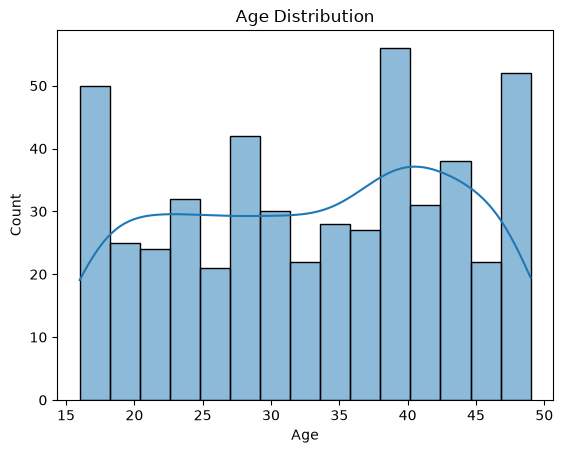

In [8]:
sns.histplot(df['Age'], bins=15, kde=True)
plt.title('Age Distribution')
plt.show()

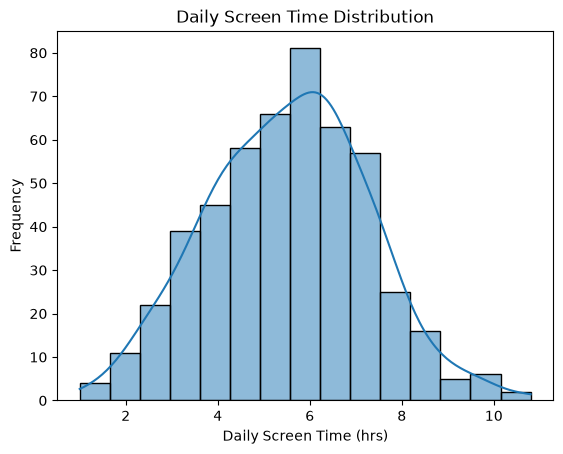

In [9]:
sns.histplot(df['Daily_Screen_Time(hrs)'], bins=15, kde=True)
plt.title('Daily Screen Time Distribution')
plt.xlabel('Daily Screen Time (hrs)')
plt.ylabel('Frequency')
plt.show()

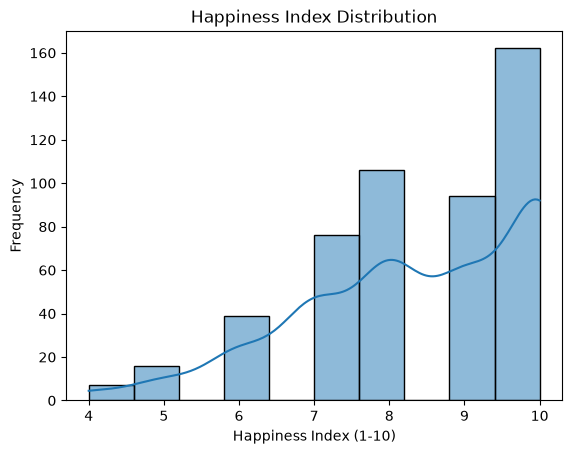

In [10]:
sns.histplot(df['Happiness_Index(1-10)'], bins=10, kde=True)
plt.title('Happiness Index Distribution')
plt.xlabel('Happiness Index (1-10)')
plt.ylabel('Frequency')
plt.show()

In [11]:
# Categorical Variable analysis
categorical_colummns= df.select_dtypes(include="object").columns 
print("categorical_colummns:",list(categorical_colummns))

categorical_colummns: ['User_ID', 'Gender', 'Social_Media_Platform']


C:\Users\ROUSHAN\AppData\Local\Temp\ipykernel_4160\3141763482.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_colummns= df.select_dtypes(include="object").columns


In [12]:
categorical_colummns = ["Gender","Social_Media_Platform"]
for column in categorical_colummns:
    print("\n", column)
    print(df[column].value_counts())


 Gender
Gender
Male      248
Female    229
Other      23
Name: count, dtype: int64

 Social_Media_Platform
Social_Media_Platform
TikTok         95
X (Twitter)    88
LinkedIn       87
Facebook       81
YouTube        75
Instagram      74
Name: count, dtype: int64


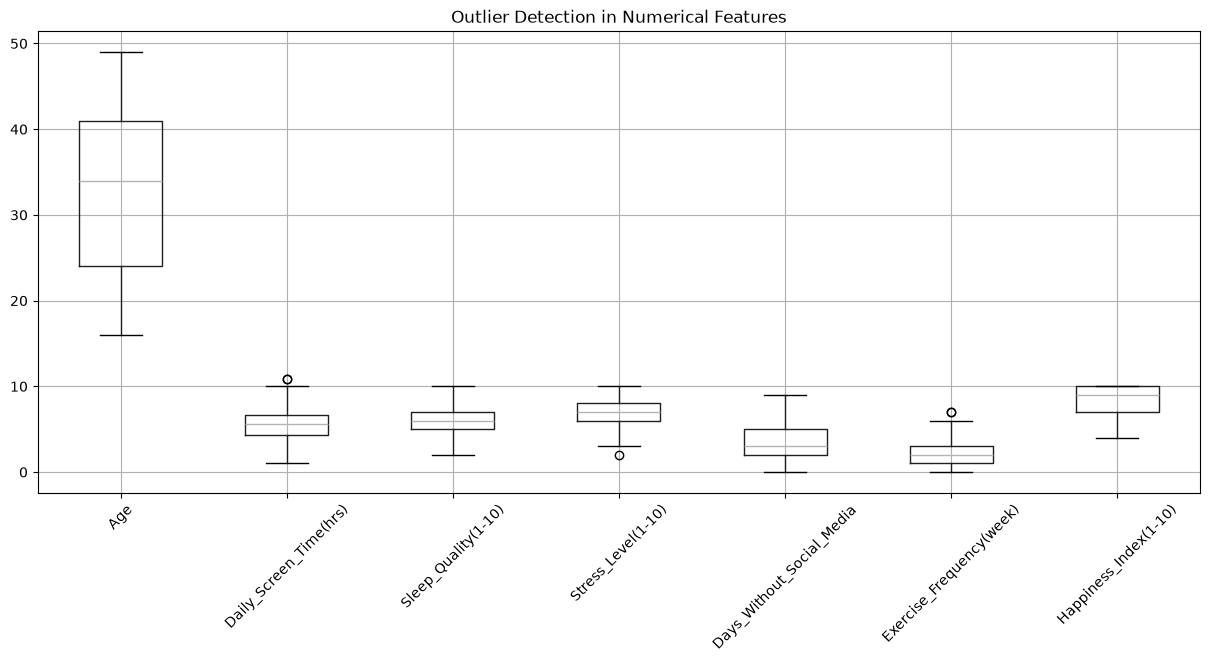

In [13]:
#Outlier Detection 
numeric_columns = ["Age",
                   "Daily_Screen_Time(hrs)",
                   "Sleep_Quality(1-10)",
                   "Stress_Level(1-10)",
                   "Days_Without_Social_Media",
                   "Exercise_Frequency(week)",
                   "Happiness_Index(1-10)"]
plt.figure(figsize=(15,6))
df[numeric_columns].boxplot()
plt.xticks(rotation=45)
plt.title("Outlier Detection in Numerical Features")
plt.show()

In [14]:
#Numerical Outlier Detection 
for column in numeric_columns:
    Q1 =df[column].quantile(0.25)
    Q3 =df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound= Q1 -1.5 * IQR
    upper_bound= Q3 + 1.5 * IQR

    outliers = df[
        (df[column]< lower_bound) |
        (df[column]> upper_bound)
    ]
    print(f"{column}: {len(outliers)} outliers")

Age: 0 outliers
Daily_Screen_Time(hrs): 2 outliers
Sleep_Quality(1-10): 0 outliers
Stress_Level(1-10): 1 outliers
Days_Without_Social_Media: 0 outliers
Exercise_Frequency(week): 2 outliers
Happiness_Index(1-10): 0 outliers


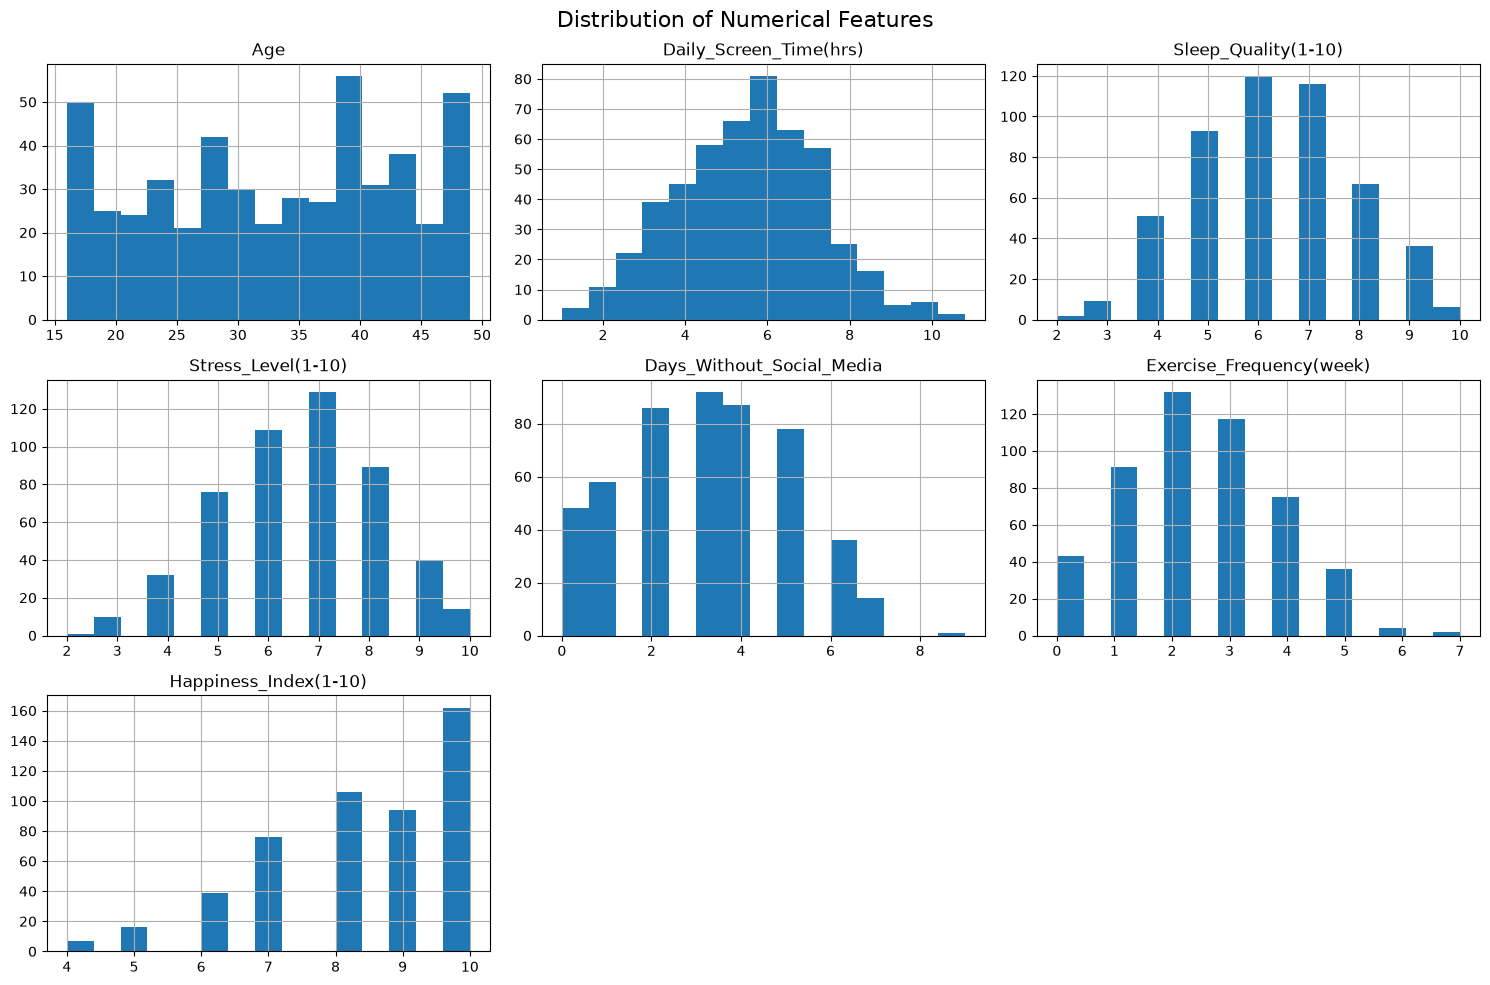

In [15]:
#Univariate Analysis
#Distribution of numerical Variables 
df[numeric_columns].hist(figsize=(15,10), bins=15)
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

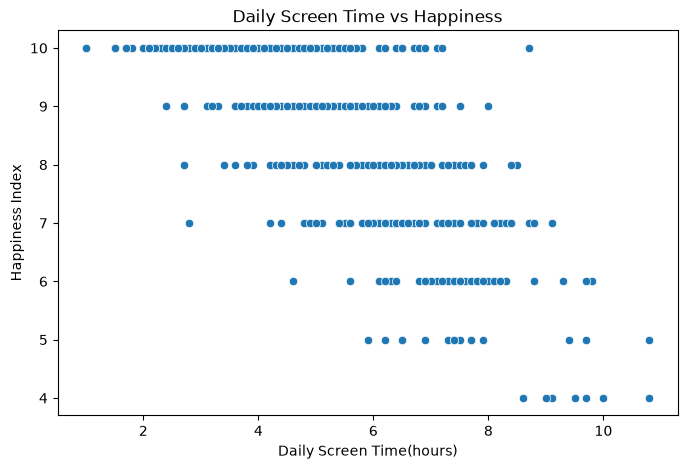

In [16]:
#Bivariate Analysis 
#Screen Time vs Happiness (Relationship between two variables)
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x="Daily_Screen_Time(hrs)",
    y="Happiness_Index(1-10)"
)
plt.title("Daily Screen Time vs Happiness")
plt.xlabel("Daily Screen Time(hours)")
plt.ylabel("Happiness Index")

plt.show()

In [17]:
correlation = df["Daily_Screen_Time(hrs)"].corr(df["Happiness_Index(1-10)"])
print("Screen Time vs Hapiness correlation :",round(correlation,3))

Screen Time vs Hapiness correlation : -0.705


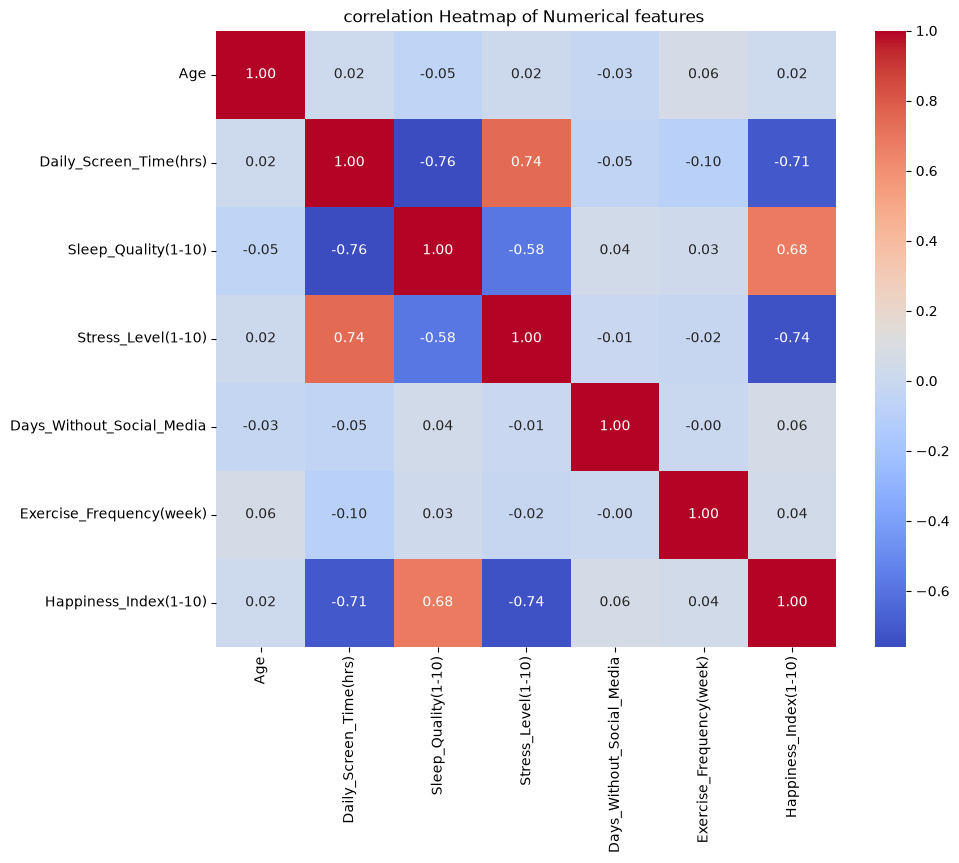

In [18]:
#Correlation heatmap
correlation_matrix = df[numeric_columns].corr()
plt.figure(figsize=(10,8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("correlation Heatmap of Numerical features ")
plt.show()

In [19]:
# Feature Engineering 
# Create a copy for MAchine Learning Preparation 
df_ml= df.copy()
# Remove USER_ID as it is only an identifier 
df_ml = df_ml.drop(columns=["User_ID"])
# Display updated Datset 
print ("original Dataset :", df.shape)
print ("ML Dataset :", df_ml.shape)
df_ml.head()
       


original Dataset : (500, 10)
ML Dataset : (500, 9)


,Age,Gender,Daily_Screen_Time(hrs),Sleep_Quality(1-10),Stress_Level(1-10),Days_Without_Social_Media,Exercise_Frequency(week),Social_Media_Platform,Happiness_Index(1-10)
0,44,Male,3.1,7.0,6.0,2.0,5.0,Facebook,10.0
1,30,Other,5.1,7.0,8.0,5.0,3.0,LinkedIn,10.0
2,23,Other,7.4,6.0,7.0,1.0,3.0,YouTube,6.0
3,36,Female,5.7,7.0,8.0,1.0,1.0,TikTok,8.0
4,34,Female,7.0,4.0,7.0,5.0,1.0,X (Twitter),8.0


In [20]:
# categorize Daily Screen Time 
df_ml["Screen_Time_Category"] = pd.cut(
    df_ml["Daily_Screen_Time(hrs)"],
    bins=[0,4,7, float("inf")],
    labels = ["Low", "Moderate","High"],
    include_lowest=True
)
# Display new Feature 
df_ml[["Daily_Screen_Time(hrs)","Screen_Time_Category"]].head(10)
# Category Defination 
# Screen Time         Category 
# Upto 4 hrs            Low
# Above 4 to 7 Hours    Moderate 
# Above 7 Hours         High

,Daily_Screen_Time(hrs),Screen_Time_Category
0,3.1,Low
1,5.1,Moderate
2,7.4,High
3,5.7,Moderate
4,7.0,Moderate
5,6.6,Moderate
6,7.8,High
7,7.4,High
8,4.7,Moderate
9,6.6,Moderate


In [21]:
# Define Input Features (X)
X = df_ml.drop(columns=["Happiness_Index(1-10)"])
# Define Target Variable (y)
y = df_ml["Happiness_Index(1-10)"]
# Display Dimensions
print("Input Features (X):", X.shape)
print("Itarget Variables (y):", y.shape)
print("\nInput Features :")
print(X.columns.tolist())
print("\nTarget Variable:")
print(y.name)


Input Features (X): (500, 9)
Itarget Variables (y): (500,)

Input Features :
['Age', 'Gender', 'Daily_Screen_Time(hrs)', 'Sleep_Quality(1-10)', 'Stress_Level(1-10)', 'Days_Without_Social_Media', 'Exercise_Frequency(week)', 'Social_Media_Platform', 'Screen_Time_Category']

Target Variable:
Happiness_Index(1-10)


In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test =train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (400, 9)
X_test: (100, 9)
y_train: (400,)
y_test: (100,)


In [23]:
#Checking Categorical features 
print("Categorical columns in X:")
print(X.select_dtypes(include="object").columns.tolist())

Categorical columns in X:
['Gender', 'Social_Media_Platform']


C:\Users\ROUSHAN\AppData\Local\Temp\ipykernel_4160\1025075525.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include="object").columns.tolist())


In [24]:
# Encoding categorical Variables | Converting "Gender" &"Socail_Media_Platform" to numerical value
X_encoded = pd.get_dummies(
    X,
    columns=["Gender", "Social_Media_Platform"],
    drop_first=True,
    dtype=int 
)
# Display encoded dataset 
print("Before Encoding:", X.shape)
print("After Encoding:", X_encoded.shape)
print("\nEncoded Columns:")
print(X_encoded.columns.tolist())
X_encoded.head()

Before Encoding: (500, 9)
After Encoding: (500, 14)

Encoded Columns:
['Age', 'Daily_Screen_Time(hrs)', 'Sleep_Quality(1-10)', 'Stress_Level(1-10)', 'Days_Without_Social_Media', 'Exercise_Frequency(week)', 'Screen_Time_Category', 'Gender_Male', 'Gender_Other', 'Social_Media_Platform_Instagram', 'Social_Media_Platform_LinkedIn', 'Social_Media_Platform_TikTok', 'Social_Media_Platform_X (Twitter)', 'Social_Media_Platform_YouTube']


,Age,Daily_Screen_Time(hrs),Sleep_Quality(1-10),Stress_Level(1-10),Days_Without_Social_Media,Exercise_Frequency(week),Screen_Time_Category,Gender_Male,Gender_Other,Social_Media_Platform_Instagram,Social_Media_Platform_LinkedIn,Social_Media_Platform_TikTok,Social_Media_Platform_X (Twitter),Social_Media_Platform_YouTube
0,44,3.1,7.0,6.0,2.0,5.0,Low,1,0,0,0,0,0,0
1,30,5.1,7.0,8.0,5.0,3.0,Moderate,0,1,0,1,0,0,0
2,23,7.4,6.0,7.0,1.0,3.0,High,0,1,0,0,0,0,1
3,36,5.7,7.0,8.0,1.0,1.0,Moderate,0,0,0,0,1,0,0
4,34,7.0,4.0,7.0,5.0,1.0,Moderate,0,0,0,0,0,1,0


In [25]:
from sklearn.preprocessing import StandardScaler
# Identify Numerical Columns 
numeric_features= X_encoded.select_dtypes(include=["int64","float64",]).columns
print("Numerical features:", numeric_features.tolist())

Numerical features: ['Age', 'Daily_Screen_Time(hrs)', 'Sleep_Quality(1-10)', 'Stress_Level(1-10)', 'Days_Without_Social_Media', 'Exercise_Frequency(week)', 'Gender_Male', 'Gender_Other', 'Social_Media_Platform_Instagram', 'Social_Media_Platform_LinkedIn', 'Social_Media_Platform_TikTok', 'Social_Media_Platform_X (Twitter)', 'Social_Media_Platform_YouTube']


In [26]:
# Initialize Standardscaler
scaler = StandardScaler()
# Fit on training data nad transform training data 
X_train_scaled= scaler.fit_transform(X_train.select_dtypes(include=["int64","float64"]))
# Transform testing data using training statstics 
X_test_scaled= scaler.transform(X_test.select_dtypes(include=["int64","float64"]))
# Check Dimensions 
print("scaled Training Data:",X_train_scaled.shape)
print("Scaled Testing Data:", X_test_scaled.shape)

scaled Training Data: (400, 6)
Scaled Testing Data: (100, 6)


In [27]:
# now we are building a proper preprocssing pipeline  using ColumnTransformer , this is important as our earlier 
# scaling excersie processed only numerical columns , the final pipeline must handle both (numrical & categorical)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
# identify  numerical and categorical features 
numeric_features = X.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Age', 'Daily_Screen_Time(hrs)', 'Sleep_Quality(1-10)', 'Stress_Level(1-10)', 'Days_Without_Social_Media', 'Exercise_Frequency(week)']
Categorical Features: ['Gender', 'Social_Media_Platform']


C:\Users\ROUSHAN\AppData\Local\Temp\ipykernel_4160\3128098644.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


In [28]:
# Define preprocessing for numerical & categorical features 
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(),numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)
print("Preprocessing Pipeline Created ")

Preprocessing Pipeline Created 


In [29]:
# Fit preprocessing on training data and transform both datasets 
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Processed Training Data:", X_train_processed.shape)
print("Processed Testing Data:", X_test_processed.shape)

Processed Training Data: (400, 15)
Processed Testing Data: (100, 15)


In [30]:
print("Training samples:", X_train_processed.shape[0])
print("Testing samples", X_test_processed.shape[0])
print("Total processed features:", X_train_processed.shape[1])
print("Target Training samples:", len(y_train))
print("Target Testing samples:", len(y_test))


Training samples: 400
Testing samples 100
Total processed features: 15
Target Training samples: 400
Target Testing samples: 100


In [31]:
#Verifying missing value 
import numpy as np
print("Missing values in processed training data:",
      np.isnan(X_train_processed).sum())
print("Missing values in processed testing data:",
      np.isnan(X_test_processed).sum())

Missing values in processed training data: 0
Missing values in processed testing data: 0


In [32]:
# Machine Learning model training 
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

print("ML models imported Successfully")

ML models imported Successfully


In [33]:
# Training Linear Regression Model 
lr_model = LinearRegression()
# Train the model 
lr_model.fit(X_train_processed, y_train) # .fit() train it using 400 training samples 
print("Linear regression model trained successfully")



Linear regression model trained successfully


In [34]:
# Random Forest 
rf_model = RandomForestRegressor(
    n_estimators=100, # Build 100 decision trees
    random_state=42  # Makes Results Reproducible 

)

rf_model.fit(X_train_processed, y_train) #.fit() trains the model on the training dataset 
print("Random Forest model trained successfully")


Random Forest model trained successfully


In [35]:
# Gradient Boosting Model 
gb_model = GradientBoostingRegressor(
    n_estimators=100, # Uses 100 boosting stages
    learning_rate=0.1, # Controls the contribution of each tree
    max_depth=3, # Limits each tree's depth
    random_state=42 #Ensures reproducibility

)

gb_model.fit(X_train_processed, y_train) #.fit() trains the model on the training dataset 
print("Gradient Boosting model trained successfully")

Gradient Boosting model trained successfully


In [36]:
# Generate prediction using all three models
y_pred_lr = lr_model.predict(X_test_processed)
y_pred_rf = rf_model.predict(X_test_processed)
y_pred_gb = gb_model.predict(X_test_processed)

print("Linear Regression Prediction:",y_pred_lr[:5])
print("Random Forest Prediction:",y_pred_rf[:5])
print("Gradient Boosting Prediction:",y_pred_gb[:5])

Linear Regression Prediction: [8.03888739 8.42649967 7.68427177 9.25883417 7.85355404]
Random Forest Prediction: [8.19 8.52 7.99 9.48 8.41]
Gradient Boosting Prediction: [8.17060442 8.76809344 8.06080928 9.76453917 7.91408653]


In [37]:
# Evaluate Model Performance 
#MAE : Mean Absolute Error , RMSE: Root Mean Squared Error , R2: Coeffient of Determination 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

#Lineear Regression 
lr_mae= mean_absolute_error(y_test, y_pred_lr)
lr_rmse= np.sqrt(mean_squared_error(y_test,y_pred_lr))
lr_r2= r2_score(y_test,y_pred_lr)

# Random Forest 
rf_mae= mean_absolute_error(y_test, y_pred_rf)
rf_rmse= np.sqrt(mean_squared_error(y_test,y_pred_rf))
rf_r2= r2_score(y_test,y_pred_rf)

# Gradeint Boosting
gb_mae= mean_absolute_error(y_test, y_pred_gb)
gb_rmse= np.sqrt(mean_squared_error(y_test,y_pred_gb))
gb_r2= r2_score(y_test,y_pred_gb)

print("LinearRegression:",lr_mae, lr_rmse , lr_r2)
print("Random Forest:",rf_mae, rf_rmse , rf_r2)
print("Gradeint Boosting:",gb_mae, gb_rmse , gb_r2)

LinearRegression: 0.7964267274149477 0.9665793299129104 0.6067201544810192
Random Forest: 0.7394999999999997 0.9186016546904322 0.6447933153729585
Gradeint Boosting: 0.7711190605182228 0.9453926014372187 0.6237720277604683


In [38]:
# Model Comparison Table
import pandas as pd
results= pd.DataFrame({
    "Model": ["LinearRegression", "RandomForest", "GradientBoosting"],
    "MAE": [lr_mae, rf_mae, gb_mae],
    "RMSE": [lr_rmse, rf_rmse, gb_rmse],
    "R2": [lr_r2, rf_r2, gb_r2]
})
results


,Model,MAE,RMSE,R2
0,LinearRegression,0.796427,0.966579,0.606720
1,RandomForest,0.739500,0.918602,0.644793
2,GradientBoosting,0.771119,0.945393,0.623772


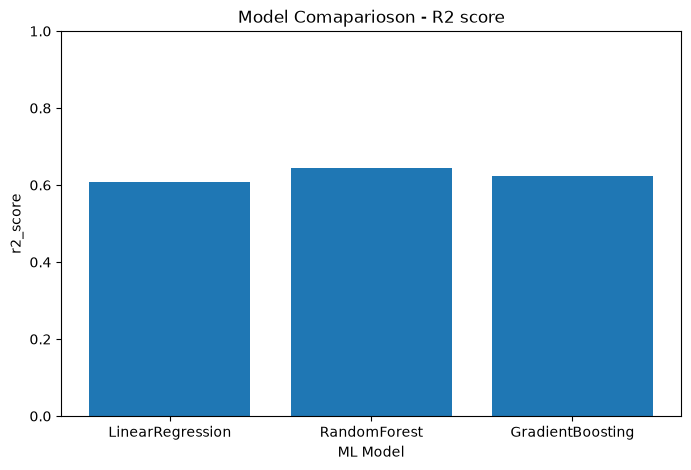

In [39]:
# Visual Model Performance for R2 scores
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.bar(results["Model"],results["R2"])
plt.title("Model Comaparioson - R2 score")
plt.xlabel("ML Model")
plt.ylabel("r2_score")

plt.ylim(0,1)
plt.show()

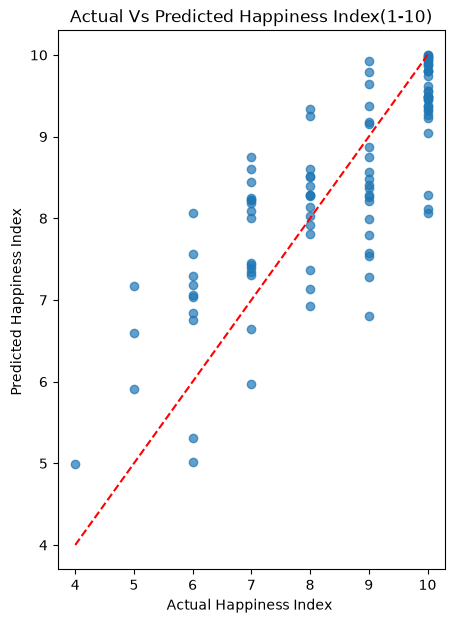

In [40]:
# Actual vs Predicted Hapiness Index 
plt.figure(figsize=(5,7))
plt.scatter(y_test, y_pred_rf, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"

)
plt.title("Actual Vs Predicted Happiness Index(1-10)")
plt.xlabel("Actual Happiness Index ")
plt.ylabel("Predicted Happiness Index ")

plt.show() 

# Red Dashed Line = Perfect Preicdtions
 # Points closer to the line = more accurate predictions 
 # Points farther Away = Larger Prediction errors 

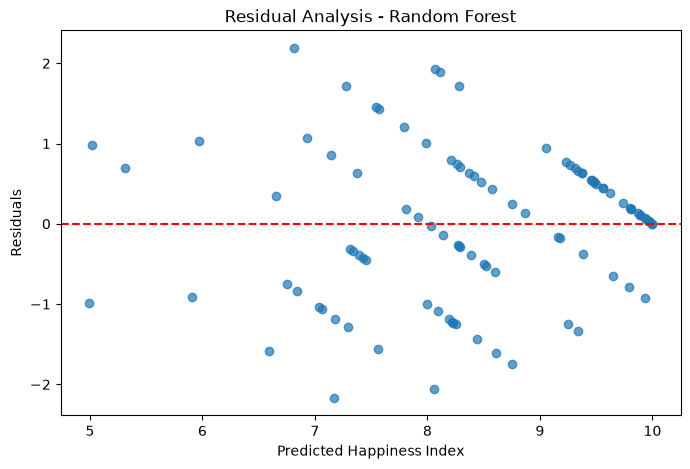

In [41]:
#Residual Error Analysis
# # Calculate residuals for Random Forest 
residuals = y_test - y_pred_rf
plt.figure(figsize=(8,5))
plt.scatter(y_pred_rf, residuals, alpha=0.7)
plt.axhline(y=0, color='red', linestyle="--")
plt.title("Residual Analysis - Random Forest")
plt.xlabel("Predicted Happiness Index")
plt.ylabel("Residuals")

plt.show()

In [42]:
#Hyperparamter Tuning 
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("Model", RandomForestRegressor(random_state=42))
])
param_grid={
    "Model__n_estimators": [100,200],
    "Model__max_depth": [None,5,10],
    "Model__min_samples_split": [2,5]
}
grid_search = GridSearchCV(
    rf_pipeline,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=1
)
grid_search.fit(X_train, y_train)

print("Best parameter:", grid_search.best_params_)
print("Best Cross-Validation R2:", grid_search.best_score_)

Best parameter: {'Model__max_depth': 5, 'Model__min_samples_split': 5, 'Model__n_estimators': 200}
Best Cross-Validation R2: 0.6094004267554999


In [43]:
print("Grid search completed:", hasattr(grid_search,"best_params_"))

Grid search completed: True


In [44]:
print(grid_search.best_params_)

{'Model__max_depth': 5, 'Model__min_samples_split': 5, 'Model__n_estimators': 200}


In [45]:
# Evaluate the tuned Random Forest 
# Get the best tuned Random Forest Model
best_rf_model = grid_search.best_estimator_
y_pred_tuned = best_rf_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test,y_pred_tuned)
tuned_rmse = np.sqrt(mean_squared_error(y_test,y_pred_tuned))
tuned_r2 = r2_score(y_test, y_pred_tuned)

print("Tuned Random forest MAE:",tuned_mae)
print("Tuned Random forest RMSE:",tuned_rmse)
print("Tuned Random forest R2:",tuned_r2)


Tuned Random forest MAE: 0.7195309127520284
Tuned Random forest RMSE: 0.8948125256271371
Tuned Random forest R2: 0.6629527462454893


In [46]:
#Comparison
final_results = pd.DataFrame({
    "Model": [
        "LinearRegression",
        "RandomForest",
        "GradientBoosting",
        "Tuned Random Forest"
    ],
    "MAE": [
        lr_mae,
        rf_mae,
        gb_mae,
        tuned_mae
    ],
    "RMSE": [
        lr_rmse,
        rf_rmse,
        gb_rmse,
        tuned_rmse
    ],
    "R2": [
        lr_r2,
        rf_r2,
        gb_r2,
        tuned_r2
    ]
})
final_results

,Model,MAE,RMSE,R2
0,LinearRegression,0.796427,0.966579,0.606720
1,RandomForest,0.739500,0.918602,0.644793
2,GradientBoosting,0.771119,0.945393,0.623772
3,Tuned Random Forest,0.719531,0.894813,0.662953


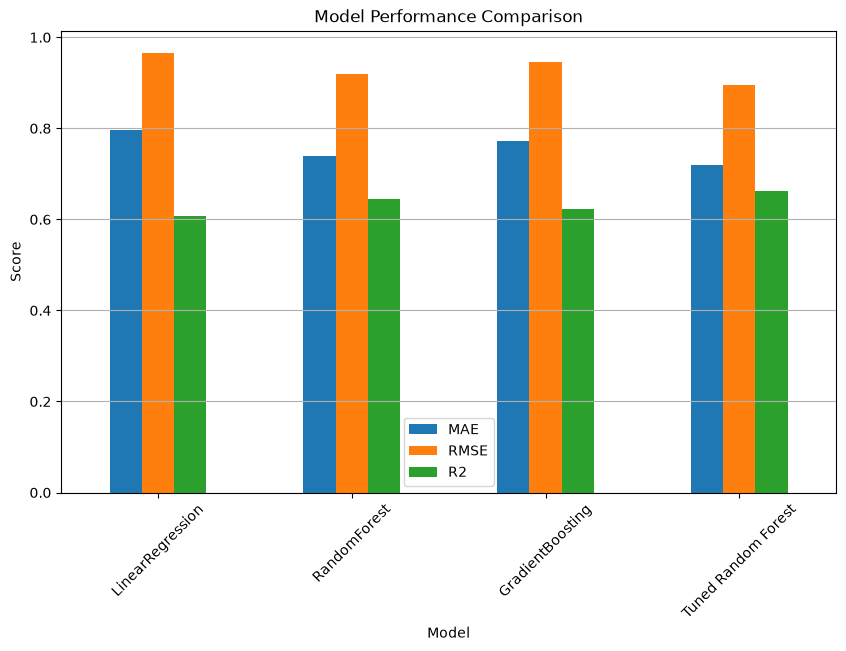

In [47]:
# Visualize Model Performance 
final_results.set_index("Model")[["MAE","RMSE","R2"]].plot(
    kind="bar",
    figsize=(10,6)

)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

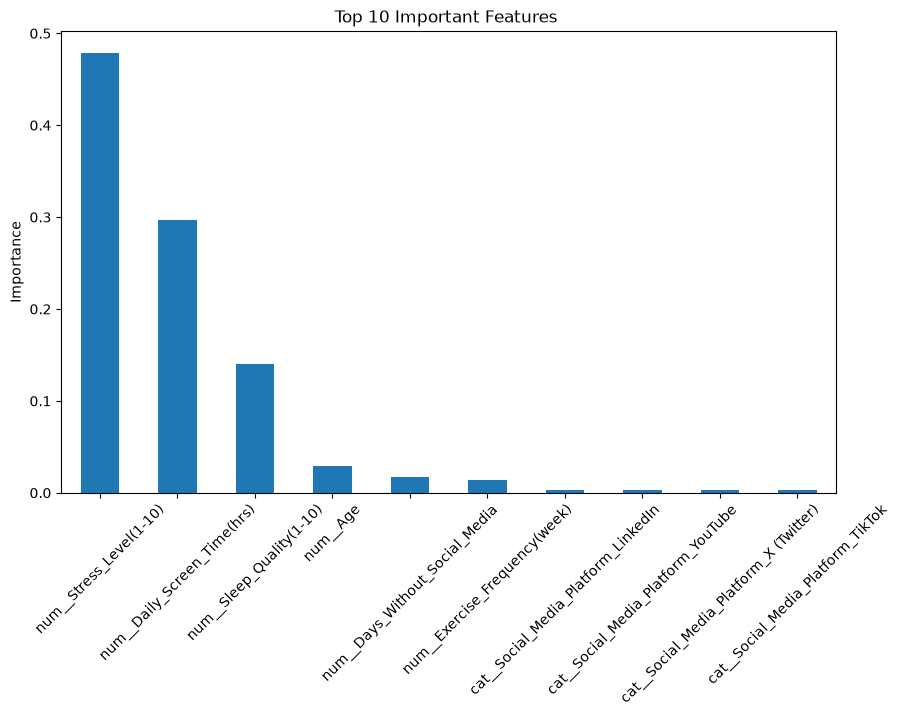

In [48]:
# Feature importnace Analysis 
feature_importance = pd.Series(
    best_rf_model.named_steps["Model"].feature_importances_,
    index = best_rf_model.named_steps["preprocessor"].get_feature_names_out()
)
feature_importance.sort_values(ascending=False).head(10).plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Top 10 Important Features ")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.show()

Feature Importance Analusis 
The feature importance analyis of the tuned random forest model indicates that Sleep Quality, Stress Level, and Daily Screen Time are the most influentail predictors of Hapiness Index. Age and social media platform - related features contribute comparatively less to the model's performance. 

Those findings suggest that Sleep Quality, stress management , and Screen Time are the importnat varibales to investigate when studying digital well-being. However, feature importace represents predictive contribution and does not establish casual reltaionships.

In [49]:
import os 
import joblib
print(os.getcwd())

c:\Users\ROUSHAN\Desktop\ASSIGNMENT\SEM 3\FDS\Project\notebooks


In [50]:
joblib.dump(best_rf_model,"../dashboards/tuned_random_forest_pipeline.pkl")

['../dashboards/tuned_random_forest_pipeline.pkl']